# Problem Definition

## Background
Pneumonia is a lung infection that inflames the air sacs and can fill them with fluid or pus. It is a leading cause of illness and death worldwide, especially in young children and older adults. Chest X-rays are the most common tool for diagnosing it, but reading them takes an experienced radiologist, and access to one is limited in many regions. Interpretation can also vary between readers and be slow when workloads are high.

## Problem Statement
Build a deep learning model that automatically classifies a chest X-ray image as **Normal** or **Pneumonia**. The goal is to support faster and more consistent screening, not to replace clinical judgment.

## Task Type
- **Learning type:** Supervised learning
- **Problem type:** Binary image classification
- **Input:** A chest X-ray image (grayscale, varying resolution)
- **Output:** Class label (`NORMAL` or `PNEUMONIA`), with a prediction probability

## Dataset
- **Source:** Chest X-Ray Images (Pneumonia) dataset on Kaggle
- **Size:** About 5,800 JPEG images split into `train`, `val` and `test` folders
- **Classes:** Normal and Pneumonia
- **Patients:** Pediatric chest X-rays (ages 1 to 5), collected at a children's medical center

## Challenges
- **Class imbalance:** Pneumonia images greatly outnumber normal ones in the training set.
- **Small validation set:** The default validation split has very few images, so it gives unreliable estimates.
- **Image variability:** Images differ in size, contrast, brightness and positioning.
- **High cost of errors:** A missed pneumonia case (false negative) is more serious than a false alarm.

## Objectives
1. Explore and visualize the dataset.
2. Preprocess the images and apply data augmentation.
3. Train and compare models (for example, a custom CNN and transfer learning).
4. Handle class imbalance (class weights, augmentation, resampling).
5. Evaluate on the held-out test set.

## Evaluation Metrics
Accuracy alone can be misleading with imbalanced classes, so the notebook will report:
- **Recall (sensitivity):** The priority, to minimize missed pneumonia cases
- **Precision**
- **F1-score**
- **Confusion matrix**
- **ROC curve and AUC**

## Success Criteria
A model that reaches high recall on the pneumonia class while keeping a good balance of precision and overall accuracy on unseen test images.

## Disclaimer
This project is for educational and research purposes only and is not a substitute for professional medical diagnosis.

In [59]:
# importing required Libraries & set seeds
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms,models
from PIL import Image
import  matplotlib.pyplot as plt
import os
import random
import numpy as np
from sklearn.metrics import f1_score, accuracy_score,recall_score,precision_score,ConfusionMatrixDisplay
seed=42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
device=("cuda" if torch.cuda.is_available() else "cpu")

In [60]:
device

'cuda'

# Load Data Paths

In [61]:
def get_data_paths(main_path):
    NORMAL_folder, PNEUMONIA_folder = "NORMAL", "PNEUMONIA"
    normal_paths=[(os.path.join(main_path,NORMAL_folder,image),0) for image in os.listdir(os.path.join(main_path,NORMAL_folder))]
    pneumnia_paths=[(os.path.join(main_path,PNEUMONIA_folder,image),1) for image in os.listdir(os.path.join(main_path,PNEUMONIA_folder))]
    random.shuffle(normal_paths)
    random.shuffle(pneumnia_paths)
    print(f"Numbe of Normal Images in that folder:{len(normal_paths)}")
    print(f"Numbe of pneumnia Images in that folder:{len(pneumnia_paths)}")
    all_paths=normal_paths+pneumnia_paths
    random.shuffle(all_paths)
    print(f"Numbe of total Images in that folder:{len(all_paths)}")
    return normal_paths,pneumnia_paths,all_paths
    
    

In [62]:
normal_paths_train,pneumnia_paths_train,all_train_paths=get_data_paths(
    "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train"
)


Numbe of Normal Images in that folder:1341
Numbe of pneumnia Images in that folder:3875
Numbe of total Images in that folder:5216


In [63]:
normal_paths_val,pneumnia_paths_val,all_val_paths=get_data_paths(
    "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/val"
)


Numbe of Normal Images in that folder:8
Numbe of pneumnia Images in that folder:8
Numbe of total Images in that folder:16


In [64]:
normal_paths_test,pneumnia_paths_test,all_test_paths=get_data_paths(
    "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/test"
)

Numbe of Normal Images in that folder:234
Numbe of pneumnia Images in that folder:390
Numbe of total Images in that folder:624


# Reconstructing train & val sets

In [65]:
merged_normal_images=normal_paths_train+normal_paths_val
merged_pneumnia_images=pneumnia_paths_train+pneumnia_paths_val
random.shuffle(merged_normal_images)
random.shuffle(merged_pneumnia_images)
train_normal_images=merged_normal_images[:int(0.85*len(merged_normal_images))]
val_normal_images=merged_normal_images[int(0.85*len(merged_normal_images)):]
train_pneumnia_images=merged_pneumnia_images[:int(0.85*len(merged_pneumnia_images))]
val_pneumnia_images=merged_pneumnia_images[int(0.85*len(merged_pneumnia_images)):]
len(train_normal_images),len(val_normal_images),len(train_pneumnia_images),len(val_pneumnia_images)


(1146, 203, 3300, 583)

In [66]:
all_train=train_normal_images+train_pneumnia_images
all_val=val_normal_images+val_pneumnia_images
random.shuffle(all_train)
random.shuffle(all_val)
len(all_train),len(all_val)

(4446, 786)

# Explore and visualize the dataset.

In [67]:
def show_images(paths):
    fig,axes=plt.subplots(nrows=4,ncols=4,figsize=(15,15))
    axes=axes.flatten()
    for i,ax in enumerate(axes):
        random_image=np.random.randint(len(paths))
        path,label=paths[random_image]
        image=Image.open(path).convert("L")
        ax.imshow(image,cmap="grey")
        ax.set_title("Normal" if label==0 else "PNEUMONIA")
    
    plt.tight_layout()
    plt.show()
        

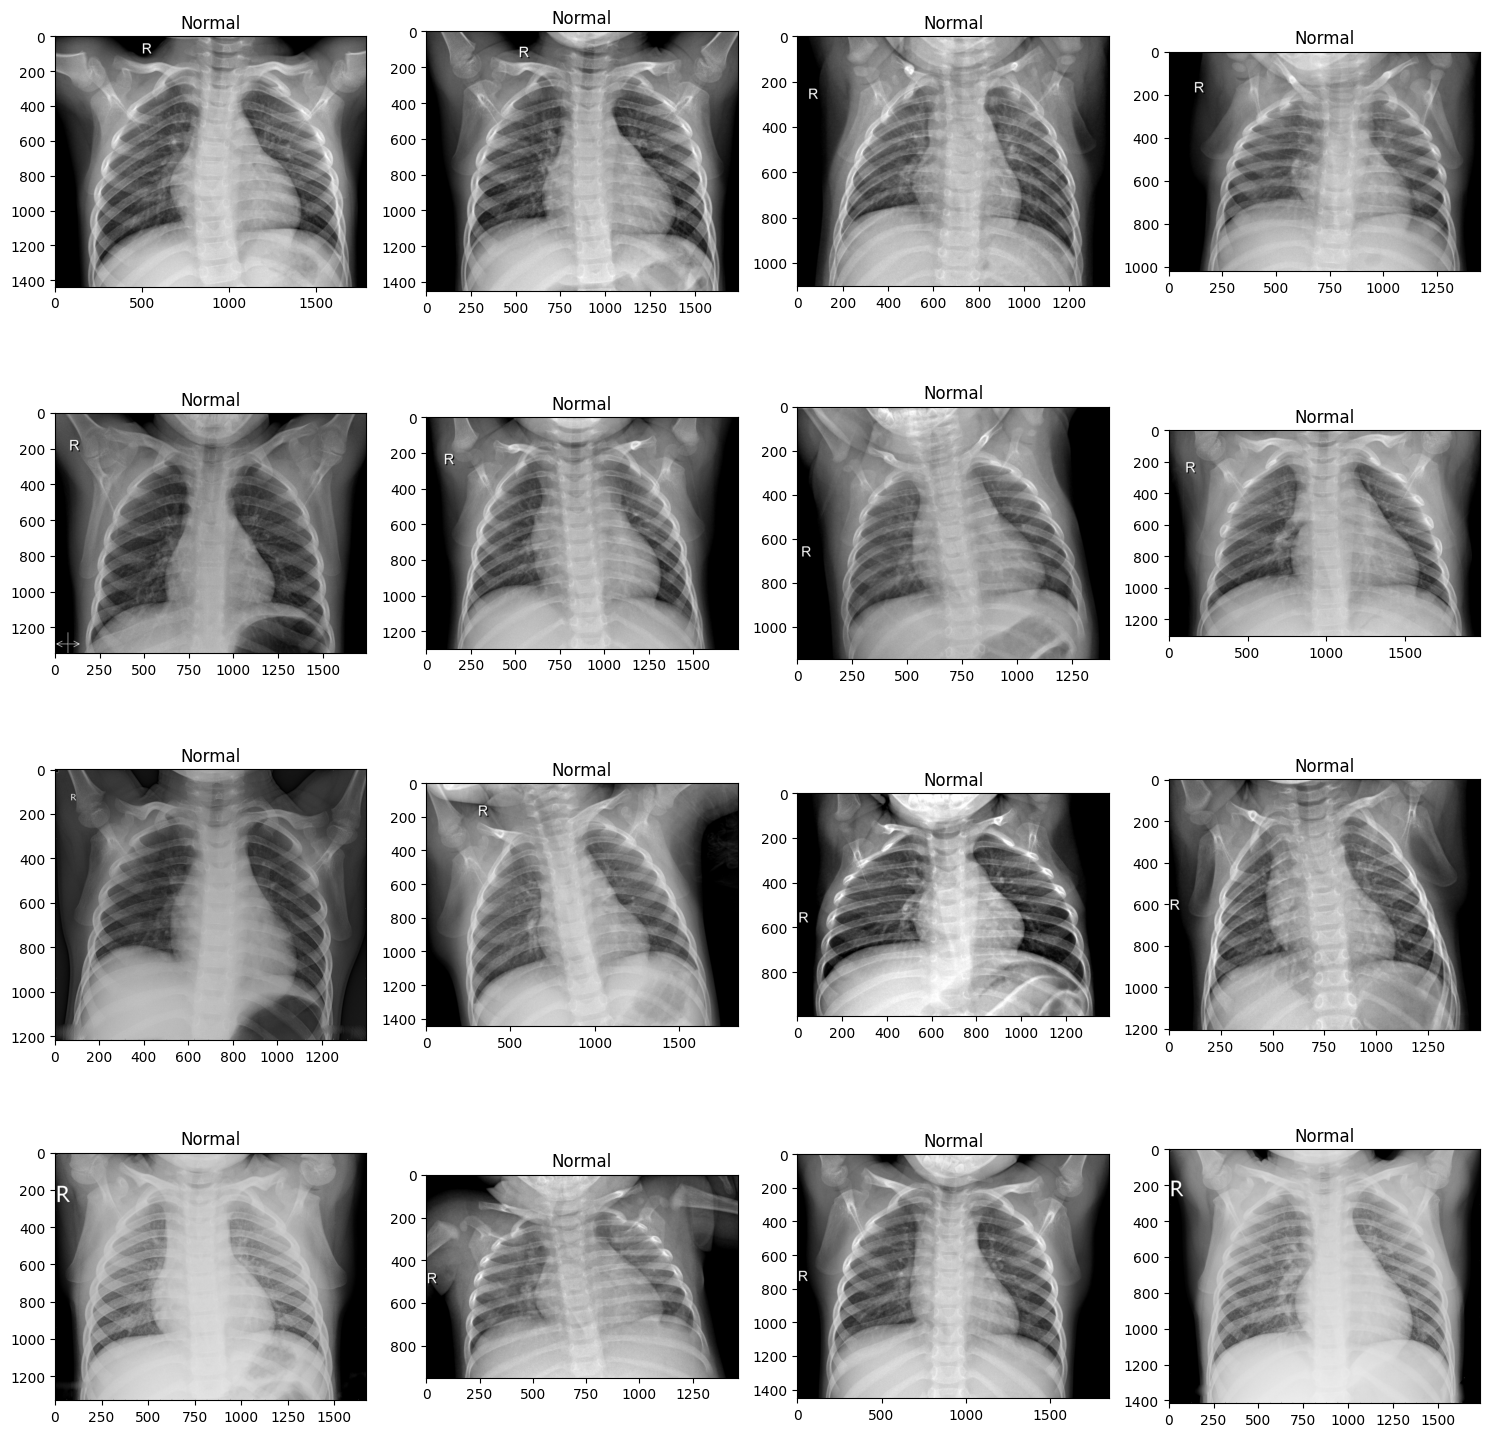

In [68]:
show_images(train_normal_images)

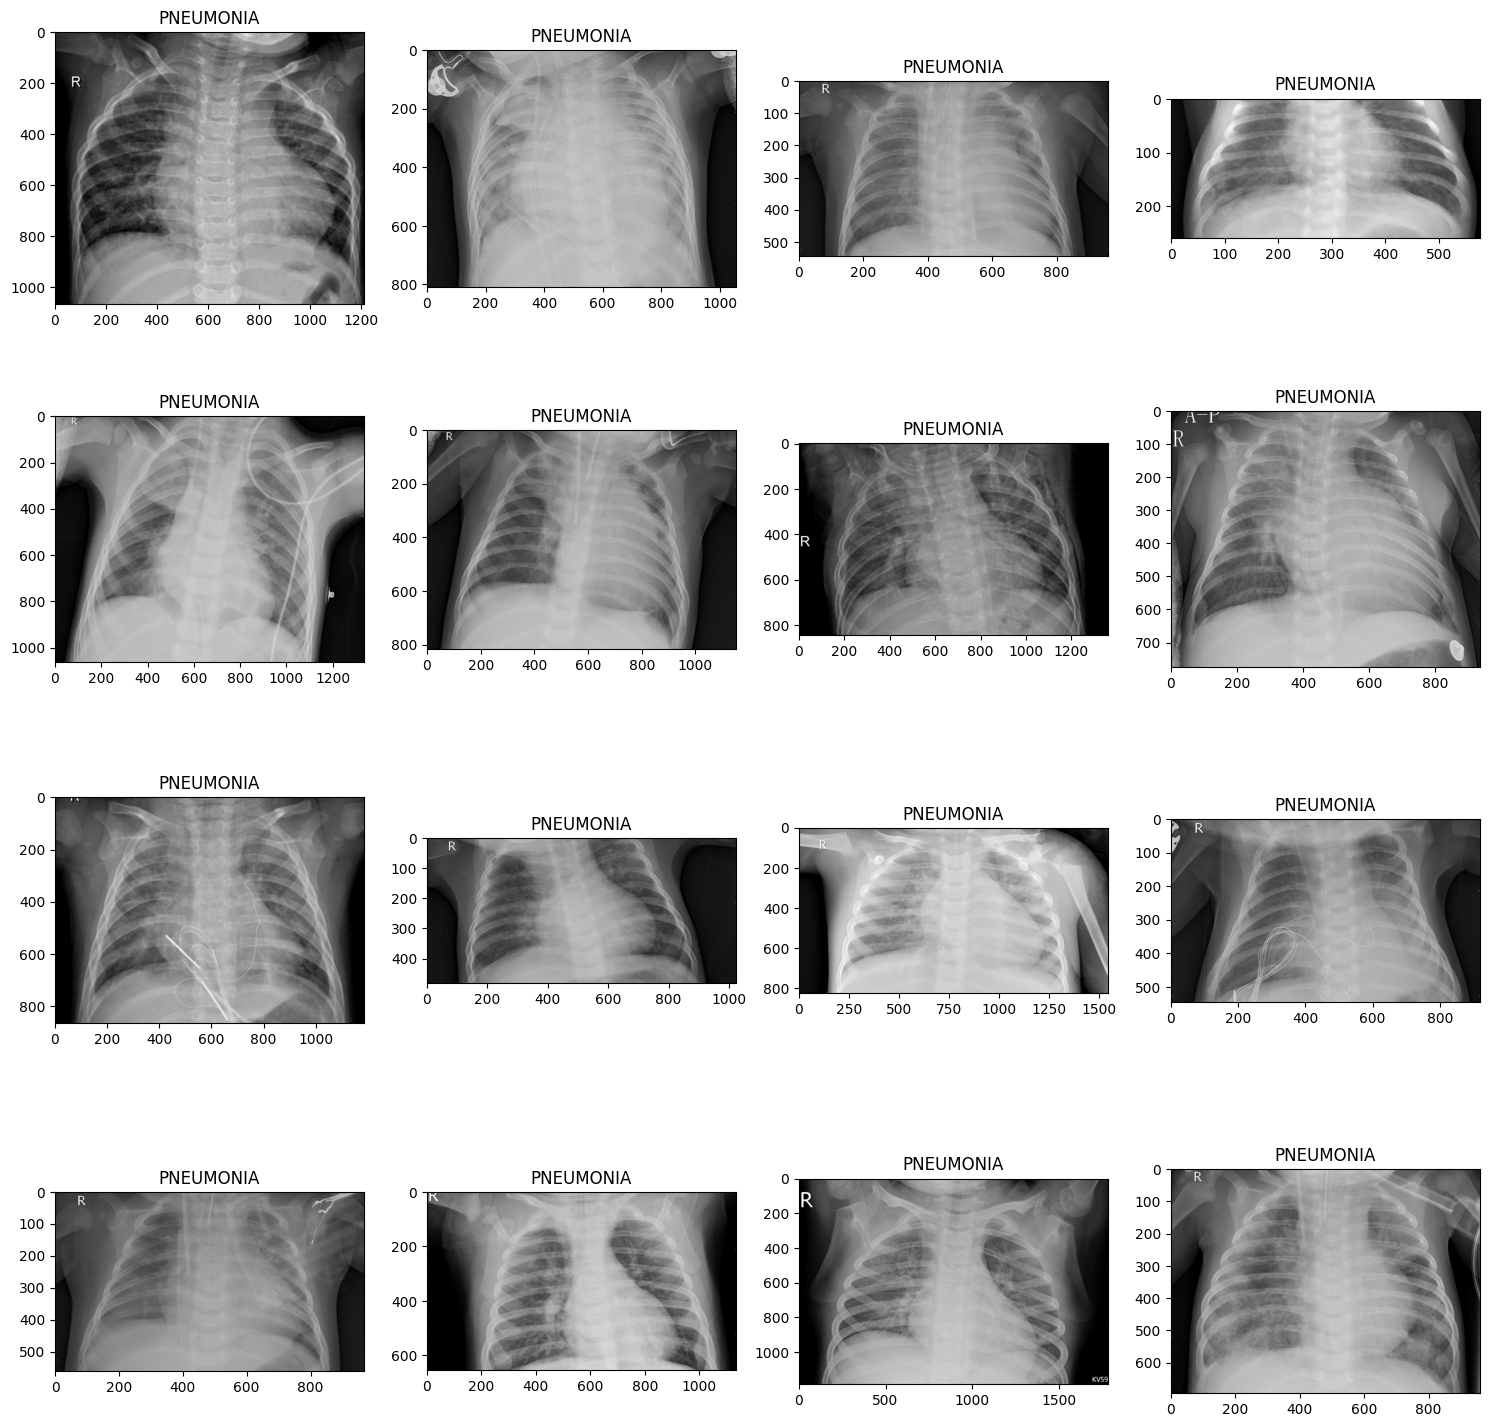

In [69]:

show_images(train_pneumnia_images)

In [70]:
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomApply([transforms.RandomRotation(10)], p=0.5),

    transforms.RandomApply([
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05))
    ], p=0.3),

    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.2, contrast=0.2)
    ], p=0.7),

    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [71]:
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [72]:
class data(Dataset):
    def __init__(self,paths,transforms):
        self.X=[x for x,_ in paths]
        self.Y=[torch.tensor(y, dtype=torch.long) for _,y in paths]
        self.transforms=transforms
    def __getitem__(self,index):
        image=Image.open(self.X[index]).convert("RGB")
        label=self.Y[index]
        if self.transforms is not None:
            image=self.transforms(image)
        return image,label    
    def __len__(self):
        return len(self.X)
        

In [73]:
train_dataset=data(all_train,train_transform)
val_dataset=data(all_val,eval_transform)

In [74]:
train_loader=DataLoader(dataset=train_dataset,shuffle=True,batch_size=64)
val_loader=DataLoader(dataset=val_dataset,shuffle=True,batch_size=64)

In [75]:
test_dataset=data(all_test_paths,eval_transform)
test_loader=DataLoader(dataset=test_dataset,shuffle=True,batch_size=64)

In [76]:
next(iter(train_loader))

[tensor([[[[-2.1179, -2.1179, -2.1179,  ..., -0.8849, -0.9363, -1.0048],
           [-2.1179, -2.1179, -2.1179,  ..., -0.8164, -0.8335, -0.9192],
           [-2.1179, -2.1179, -2.1179,  ..., -0.6965, -0.6794, -0.7650],
           ...,
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
           [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179]],
 
          [[-2.0357, -2.0357, -2.0357,  ..., -0.7752, -0.8277, -0.8978],
           [-2.0357, -2.0357, -2.0357,  ..., -0.7052, -0.7227, -0.8102],
           [-2.0357, -2.0357, -2.0357,  ..., -0.5826, -0.5651, -0.6527],
           ...,
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
           [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357]],
 
          [[-1.8044, -1.8044, -1.8044,  ..., -0.5495, -0.6018, -0.6715],
           [-

In [87]:
class TinyVGG(nn.Module):
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.constant_(m.bias, 0)
                
    def __init__(self,input_shape=3,hidden_units=10, output_shape=2):
        super().__init__()
        self.Conv_block1=nn.Sequential(
            nn.Conv2d(in_channels=input_shape,out_channels=hidden_units,
                     kernel_size=3,stride=1,padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,
                     kernel_size=3,stride=1,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(stride=2,kernel_size=2)

        )
        self.Conv_block2=nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,
                     kernel_size=3,stride=1,padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,out_channels=hidden_units,
                     kernel_size=3,stride=1,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(stride=2,kernel_size=2)         
        )  
        self.Classifier=nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(in_features=hidden_units*56*56,
                      out_features=output_shape)
        )  
        self._init_weights()
    def forward(self,x):
            return self.Classifier(self.Conv_block2(self.Conv_block1(x)))
        

In [88]:
tinyvgg=TinyVGG()
criterion=nn.CrossEntropyLoss()


In [89]:
optim=torch.optim.Adam(tinyvgg.parameters(),lr=0.001)

In [124]:
import copy
def train_Model(model,criterion,optim,train_loader,test_loader,n_epochs): 
    model.to(device)
    Train_loss_buffer=[]
    Test_loss_buffer=[]
    BestModel=None
    bestf1=-1
    for epoch in range(n_epochs):
        train_loss=0
        correct_train_predictions=0
        n_train_samples=0
        model.train(True)
        for batch,(X,Y)in enumerate(train_loader):
            X=X.to(device)
            Y=Y.to(device)
            train_predictions=model(X)
            loss=criterion(train_predictions,Y)
            train_loss+=loss.item()
            optim.zero_grad()
            loss.backward()
            optim.step()
            train_predictions=torch.argmax(train_predictions,dim=1)
            correct_train_predictions+=(train_predictions==Y).sum().item()
            n_train_samples+=len(Y)
            if (batch%25==0):
                print(f"Epoch {epoch+1}: Batch {batch}/{len(train_loader)} | Loss {loss.item():.4f}")
        Average_train_Loss= train_loss/  len(train_loader)
        training_acc=correct_train_predictions/n_train_samples
        Train_loss_buffer.append(Average_train_Loss)
        test_loss=0
        correct_test_predictions=0
        n_test_samples=0
        all_predictions=[]
        all_true=[]
        model.eval()
        with torch.no_grad():
            for batch,(X,Y)in enumerate(test_loader):
                X=X.to(device)
                Y=Y.to(device)
                test_predictions=model(X)
                loss=criterion(test_predictions,Y)
                test_loss+=loss.item()
                test_predictions=torch.argmax(test_predictions,dim=1)
                correct_test_predictions+=(test_predictions==Y).sum().item()
                n_test_samples+=len(Y)
                all_predictions.extend(test_predictions.cpu().tolist())
                all_true.extend(Y.cpu().tolist())
        Average_test_Loss= test_loss/  len(test_loader)
        testing_acc=correct_test_predictions/n_test_samples
        Test_loss_buffer.append(Average_test_Loss)
        f1=f1_score(all_true, all_predictions)
        if f1>bestf1:
             BestModel = copy.deepcopy(model.state_dict())
             bestf1 = f1
        print(f"Epoch {epoch+1}/{n_epochs} | "
              f"train loss {Average_train_Loss:.4f} acc {training_acc*100:.3f} | "
              f"test loss {Average_test_Loss:.4f} acc {testing_acc*100:.3f} f1={f1}")
            
            
    return Train_loss_buffer,Test_loss_buffer ,BestModel

# Evaluate Model

In [91]:

def Evaluate_model(model,loader):
    model.to(device)
    model.eval()
    with torch.no_grad():
        all_predictions=[]
        all_true=[]
        for _,(X,Y) in enumerate(loader):
            X=X.to(device)
            Y=Y.to(device)
            predictions=torch.argmax(model(X),dim=1)
            all_predictions.extend(predictions.cpu().tolist())
            all_true.extend(Y.cpu().tolist())
        
    print(f"Recall    : {recall_score(all_true, all_predictions):.4f}")
    print(f"Precision : {precision_score(all_true, all_predictions):.4f}")
    print(f"Accuracy  : {accuracy_score(all_true, all_predictions):.4f}")
    print(f"F1-score  : {f1_score(all_true, all_predictions):.4f}")
    ConfusionMatrixDisplay.from_predictions(
        all_true, all_predictions,
        display_labels=["NORMAL", "PNEUMONIA"]
    )
    plt.show()
   


        
        
        
    

In [92]:
Train_losses,Val_losses,best_Model=train_Model(tinyvgg,criterion,optim,train_loader,val_loader,n_epochs=10)

Epoch 1: Batch 0/70 | Loss 0.7529
Epoch 1: Batch 25/70 | Loss 0.1298
Epoch 1: Batch 50/70 | Loss 0.0859
Epoch 1/10 | train loss 0.2749 acc 90.171 | test loss 0.1015 acc 95.420 f1=0.9698492462311558
Epoch 2: Batch 0/70 | Loss 0.1076
Epoch 2: Batch 25/70 | Loss 0.0935
Epoch 2: Batch 50/70 | Loss 0.1359
Epoch 2/10 | train loss 0.1335 acc 94.647 | test loss 0.0797 acc 97.837 f1=0.9852813852813853
Epoch 3: Batch 0/70 | Loss 0.1234
Epoch 3: Batch 25/70 | Loss 0.0937
Epoch 3: Batch 50/70 | Loss 0.0717
Epoch 3/10 | train loss 0.1223 acc 95.592 | test loss 0.0708 acc 98.092 f1=0.9871023215821152
Epoch 4: Batch 0/70 | Loss 0.0907
Epoch 4: Batch 25/70 | Loss 0.0605
Epoch 4: Batch 50/70 | Loss 0.2223
Epoch 4/10 | train loss 0.1113 acc 95.839 | test loss 0.0540 acc 98.092 f1=0.9871685201026519
Epoch 5: Batch 0/70 | Loss 0.1194
Epoch 5: Batch 25/70 | Loss 0.0596
Epoch 5: Batch 50/70 | Loss 0.0563
Epoch 5/10 | train loss 0.1048 acc 96.064 | test loss 0.0476 acc 98.601 f1=0.9905579399141631
Epoch 6: B

Recall    : 0.9885
Precision : 0.9740
Accuracy  : 0.9719
F1-score  : 0.9812


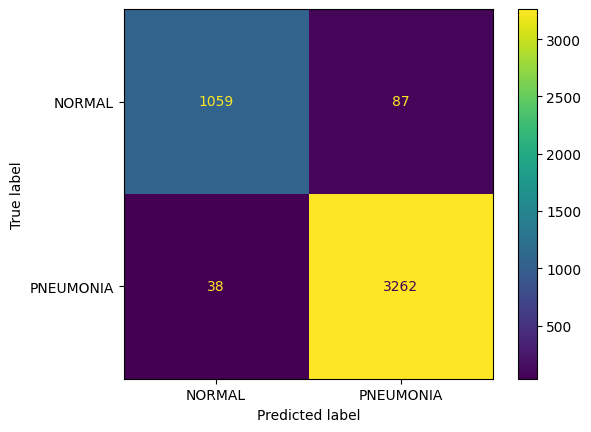

In [99]:
Evaluate_model(best_Model,train_loader)

Recall    : 0.9897
Precision : 0.9931
Accuracy  : 0.9873
F1-score  : 0.9914


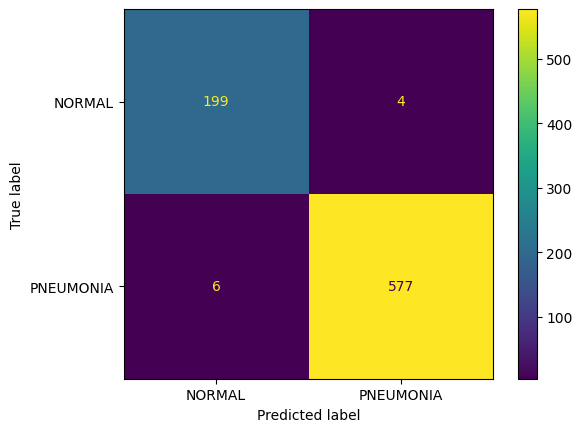

In [100]:
Evaluate_model(best_Model,val_loader)

Recall    : 0.9974
Precision : 0.7138
Accuracy  : 0.7484
F1-score  : 0.8321


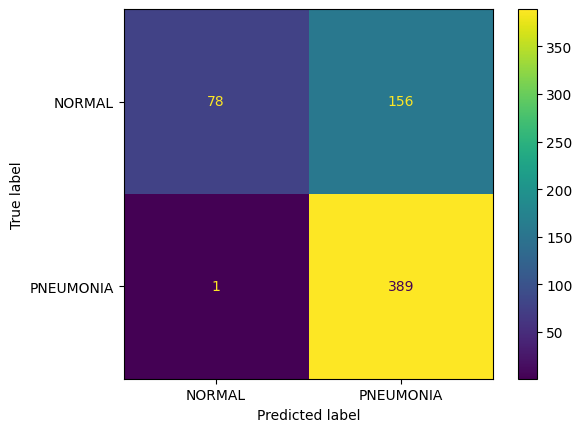

In [101]:
Evaluate_model(best_Model,test_loader)

# Transfer Learning

In [133]:
weights = models.VGG16_Weights.IMAGENET1K_V1
VGG = models.vgg16(weights=weights)


In [134]:
for parameter in VGG.parameters():
    parameter.requires_grad = False
    

In [135]:
VGG

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [136]:
for p in VGG.classifier.parameters():
    p.requires_grad = True
VGG.classifier[6]=nn.Sequential(
    nn.Linear(4096,1000),
    nn.ReLU(),
    nn.Dropout(p=0.5, inplace=False),
    nn.Linear(1000,500),
    nn.ReLU(),
    nn.Dropout(p=0.5, inplace=False),
    nn.Linear(500,100),
    nn.ReLU(),
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(100,50),
    nn.ReLU(),
    nn.Linear(50,2),
     
)
VGG = VGG.to(device)

In [137]:
VGG

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [123]:
optim=torch.optim.Adam(VGG.parameters(),lr=0.0001)

In [125]:
Train_losses,Val_losses,best_Model=train_Model(VGG,criterion,optim,train_loader,val_loader,n_epochs=10)

Epoch 1: Batch 0/70 | Loss 0.6886
Epoch 1: Batch 25/70 | Loss 0.2784
Epoch 1: Batch 50/70 | Loss 0.2466
Epoch 1/10 | train loss 0.3111 acc 84.503 | test loss 0.0605 acc 98.092 f1=0.9871244635193133
Epoch 2: Batch 0/70 | Loss 0.0900
Epoch 2: Batch 25/70 | Loss 0.1031
Epoch 2: Batch 50/70 | Loss 0.0620
Epoch 2/10 | train loss 0.1025 acc 96.739 | test loss 0.0437 acc 98.346 f1=0.9887834339948232
Epoch 3: Batch 0/70 | Loss 0.0940
Epoch 3: Batch 25/70 | Loss 0.0244
Epoch 3: Batch 50/70 | Loss 0.1104
Epoch 3/10 | train loss 0.0785 acc 97.188 | test loss 0.0312 acc 98.855 f1=0.9922346850733391
Epoch 4: Batch 0/70 | Loss 0.0669
Epoch 4: Batch 25/70 | Loss 0.0090
Epoch 4: Batch 50/70 | Loss 0.0570
Epoch 4/10 | train loss 0.0603 acc 97.773 | test loss 0.0393 acc 98.601 f1=0.9904761904761905
Epoch 5: Batch 0/70 | Loss 0.0640
Epoch 5: Batch 25/70 | Loss 0.0866
Epoch 5: Batch 50/70 | Loss 0.0147
Epoch 5/10 | train loss 0.0585 acc 97.931 | test loss 0.0422 acc 98.473 f1=0.989778534923339
Epoch 6: Ba

In [138]:
VGG.load_state_dict(best_Model)

<All keys matched successfully>

Recall    : 0.9942
Precision : 0.9951
Accuracy  : 0.9921
F1-score  : 0.9947


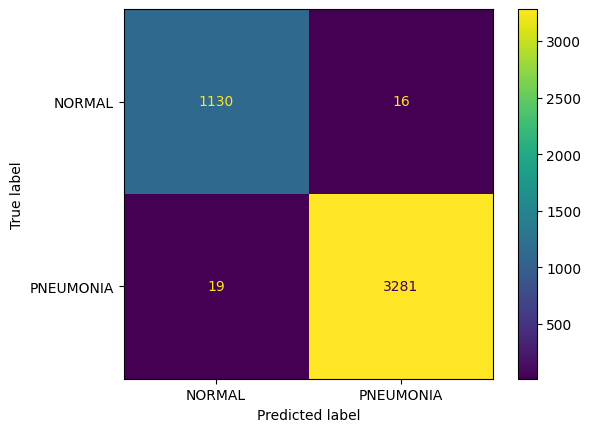

In [139]:
Evaluate_model(VGG,train_loader)

Recall    : 0.9880
Precision : 0.9983
Accuracy  : 0.9898
F1-score  : 0.9931


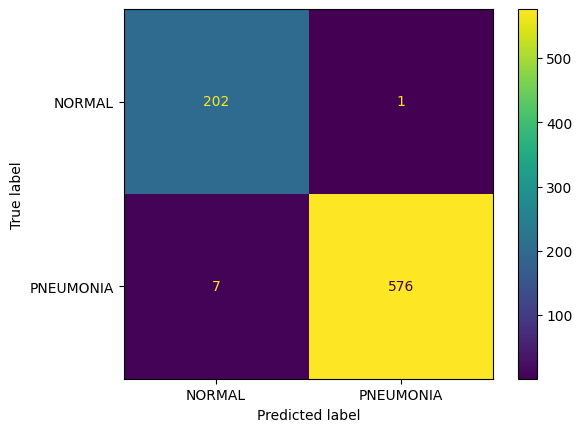

In [140]:
Evaluate_model(VGG,val_loader)

Recall    : 0.9974
Precision : 0.7811
Accuracy  : 0.8237
F1-score  : 0.8761


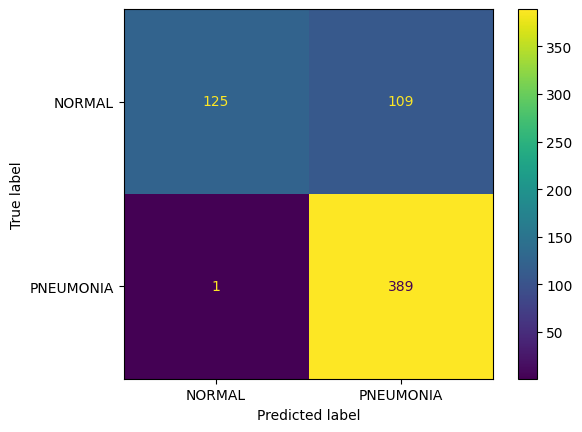

In [141]:
Evaluate_model(VGG,test_loader)

# Fine Tunning

Trainable: 131,278,032 / 138,913,296
Epoch 1: Batch 0/70 | Loss 0.0425
Epoch 1: Batch 25/70 | Loss 0.0345
Epoch 1: Batch 50/70 | Loss 0.0060
Epoch 1/10 | train loss 0.0407 acc 98.650 | test loss 0.0422 acc 98.728 f1=0.9913494809688581
Epoch 2: Batch 0/70 | Loss 0.0172
Epoch 2: Batch 25/70 | Loss 0.1279
Epoch 2: Batch 50/70 | Loss 0.0345
Epoch 2/10 | train loss 0.0380 acc 98.583 | test loss 0.0340 acc 98.855 f1=0.9922480620155039
Epoch 3: Batch 0/70 | Loss 0.0056
Epoch 3: Batch 25/70 | Loss 0.0456
Epoch 3: Batch 50/70 | Loss 0.0272
Epoch 3/10 | train loss 0.0294 acc 98.808 | test loss 0.0663 acc 98.473 f1=0.9896013864818024
Epoch 4: Batch 0/70 | Loss 0.0428
Epoch 4: Batch 25/70 | Loss 0.0095
Epoch 4: Batch 50/70 | Loss 0.0822
Epoch 4/10 | train loss 0.0352 acc 98.583 | test loss 0.0298 acc 99.237 f1=0.9948453608247423
Epoch 5: Batch 0/70 | Loss 0.0327
Epoch 5: Batch 25/70 | Loss 0.0102
Epoch 5: Batch 50/70 | Loss 0.0001
Epoch 5/10 | train loss 0.0257 acc 99.033 | test loss 0.0343 acc 99

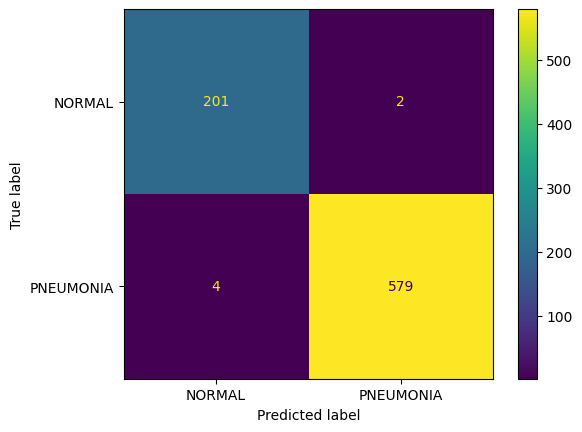

Recall    : 0.9974
Precision : 0.7703
Accuracy  : 0.8125
F1-score  : 0.8693


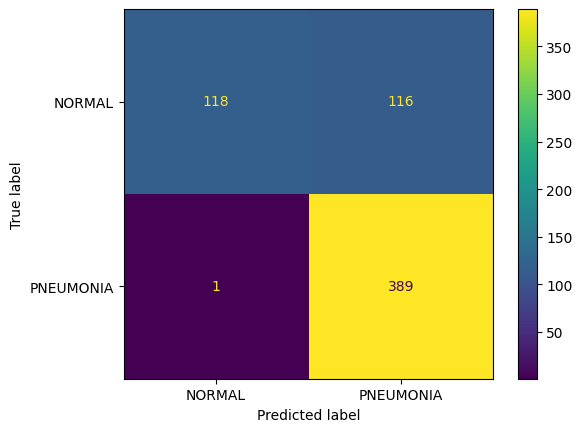

In [142]:

for p in VGG.features.parameters():
    p.requires_grad = False
for p in VGG.features[24:].parameters():
    p.requires_grad = True
for p in VGG.classifier.parameters():
    p.requires_grad = True

trainable = sum(p.numel() for p in VGG.parameters() if p.requires_grad)
total = sum(p.numel() for p in VGG.parameters())
print(f"Trainable: {trainable:,} / {total:,}")


optim = torch.optim.Adam([
    {"params": VGG.features[24:].parameters(), "lr": 1e-5},
    {"params": VGG.classifier.parameters(),    "lr": 1e-4},
])

# 4. Train (reuses your train_Model, which keeps the best epoch by val F1)
Train_losses, Val_losses, best_Model = train_Model(
    VGG, criterion, optim, train_loader, val_loader, n_epochs=10
)


VGG.load_state_dict(best_Model)
torch.save(best_Model, "best_vgg_finetuned.pth")

Evaluate_model(VGG, val_loader)
Evaluate_model(VGG, test_loader)